# Optimización bayesiana de hiperparámetros con Optuna

### Setup, Carga de Datos y Pipeline de Preprocesamiento

In [8]:
import os
import optuna
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
from google.cloud import bigquery
from pathlib import Path

# Preprocesamiento y métricas
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, roc_auc_score, f1_score, precision_recall_curve
from xgboost import XGBClassifier

# Silenciar logs de Optuna para mayor claridad
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Estilos visuales
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

# Cargar variables de entorno y conexión BQ
load_dotenv('../.env')
credentials_path = os.getenv('GOOGLE_APPLICATION_CREDENTIALS')
if credentials_path and not os.path.isabs(credentials_path):
    os.environ['GOOGLE_APPLICATION_CREDENTIALS'] = os.path.abspath(os.path.join('..', credentials_path))

PROJECT_ID = os.getenv('GCP_PROJECT_ID')
DATASET_ID = os.getenv('GCP_DATASET_ID')
TABLE_NAME = 'telco_churn_features'

client = bigquery.Client(project=PROJECT_ID)
query = f'SELECT * FROM `{PROJECT_ID}.{DATASET_ID}.{TABLE_NAME}`'
df = client.query(query).to_dataframe()

print(f"Datos cargados desde BigQuery: {df.shape[0]} filas x {df.shape[1]} columnas.")

Datos cargados desde BigQuery: 7043 filas x 33 columnas.


### Aislamiento de Variables, Split y Preprocesador

In [3]:
drop_cols = [
    'customer_id', 'country', 'state', 'city', 'zip_code',
    'latitude', 'longitude', 'cltv', 'monthly_to_avg_charge_ratio',
    'churn_target'
]

X = df.drop(columns=drop_cols)
y = df['churn_target']

columnas_numericas = X.select_dtypes(include=[np.number]).columns.tolist()
columnas_categoricas = X.select_dtypes(exclude=[np.number]).columns.tolist()

# Split 80/20 idéntico al notebook 2
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# Pipeline de preprocesamiento modular
tranformador_numerico = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

tranformador_categorico = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Not Specified')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False))
])

preprocesador = ColumnTransformer(
    transformers=[
        ('num', tranformador_numerico, columnas_numericas),
        ('cat', tranformador_categorico, columnas_categoricas)
    ],
    remainder='drop'
)

# Preprocesamos X_train y X_test una sola vez antes de la optimización bayesiana para maximizar velocidad
X_train_proc = preprocesador.fit_transform(X_train)
X_test_proc = preprocesador.transform(X_test)

print(f"Matriz de entrenamiento procesada: {X_train_proc.shape[0]:,} muestras x {X_train_proc.shape[1]} columnas OHE.")

Matriz de entrenamiento procesada: 5,634 muestras x 36 columnas OHE.


### Definición del Estudio Optuna con Validación Cruzada Estratificada

In [4]:
ratio_desbalance = (len(y_train) - sum(y_train)) / sum(y_train)

def objetivo(trial):
    # Espacio de búsqueda de hiperparámetros
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.4, 1.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'gamma': trial.suggest_float('gamma', 0.0, 5.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1.0, ratio_desbalance * 1.5),
        'eval_metric': 'logloss',
        'random_state': 42,
        'n_jobs': -1
    }
    
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    pr_auc_scores = []
    
    for train_idx, val_idx in cv.split(X_train_proc, y_train):
        X_fold_train, X_fold_val = X_train_proc[train_idx], X_train_proc[val_idx]
        y_fold_train, y_fold_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
        
        clf = XGBClassifier(**params)
        clf.fit(X_fold_train, y_fold_train)
        
        y_val_proba = clf.predict_proba(X_fold_val)[:, 1]
        score = average_precision_score(y_fold_val, y_val_proba)
        pr_auc_scores.append(score)
        
    return np.mean(pr_auc_scores)

# Ejecutar el estudio (50 trials es un balance ideal de tiempo y exploración)
print("Iniciando optimización bayesiana con Optuna (50 trials)...")
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objetivo, n_trials=50, timeout=600)

print(f"\nOptimización finalizada.")
print(f"Mejor PR-AUC promedio en CV: {study.best_value:.4f}")
print("Mejores Hiperparámetros encontrados:")
for k, v in study.best_params.items():
    print(f"   * {k}: {v}")

Iniciando optimización bayesiana con Optuna (50 trials)...

Optimización finalizada.
Mejor PR-AUC promedio en CV: 0.6877
Mejores Hiperparámetros encontrados:
   * n_estimators: 350
   * max_depth: 7
   * learning_rate: 0.01473026157516205
   * subsample: 0.9556329307471025
   * colsample_bytree: 0.45347376525780564
   * min_child_weight: 9
   * gamma: 2.130866532851881
   * reg_alpha: 0.5658660020231598
   * reg_lambda: 0.009518453499671706
   * scale_pos_weight: 1.5931055266606173


### Evaluación Final contra el Baseline de Regresión Logística

In [6]:
# 1. Entrenar el mejor XGBoost con los hiperparámetros ganadores
best_xgb_params = study.best_params
best_xgb_params.update({'eval_metric': 'logloss', 'random_state': 42, 'n_jobs': -1})

best_xgb = XGBClassifier(**best_xgb_params)
best_xgb.fit(X_train_proc, y_train)

# Predicciones sobre Test Set
y_test_proba_xgb = best_xgb.predict_proba(X_test_proc)[:, 1]
y_test_pred_xgb = best_xgb.predict(X_test_proc)

# 2. Re-entrenar Regresión Logística (Baseline de referencia)
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr.fit(X_train_proc, y_train)

y_test_proba_lr = lr.predict_proba(X_test_proc)[:, 1]
y_test_pred_lr = lr.predict(X_test_proc)

# 3. Comparativa en Test Set
comparativa = pd.DataFrame([
    {
        'Modelo': 'Logistic Regression (Baseline)',
        'ROC-AUC': round(roc_auc_score(y_test, y_test_proba_lr), 4),
        'PR-AUC': round(average_precision_score(y_test, y_test_proba_lr), 4),
        'F1-Score': round(f1_score(y_test, y_test_pred_lr), 4)
    },
    {
        'Modelo': 'XGBoost Tuned (Optuna)',
        'ROC-AUC': round(roc_auc_score(y_test, y_test_proba_xgb), 4),
        'PR-AUC': round(average_precision_score(y_test, y_test_proba_xgb), 4),
        'F1-Score': round(f1_score(y_test, y_test_pred_xgb), 4)
    }
]).sort_values(by='PR-AUC',ascending=False)

display(comparativa)

,Modelo,ROC-AUC,PR-AUC,F1-Score
1,XGBoost Tuned (Optuna),0.8434,0.6817,0.6120
0,Logistic Regression (Baseline),0.8362,0.6653,0.6105


### Veredicto de la Optimización Bayesiana

1. **Superación del Baseline:**
   * La optimización con Optuna permitió a XGBoost superar consistentemente a la Regresión Logística en el conjunto de prueba:
     * **PR-AUC:** aumentó de **0.6653 a 0.6817** (+1.64 pp directos en la clase minoritaria).
     * **ROC-AUC:** subió de **0.8362 a 0.8434**.
     * **F1-Score:** alcanzó **0.6120**.

2. **Control del Sobreajuste (Regularización Bayesiana):**
   * Optuna encontró una combinación con tasa de aprendizaje baja (`learning_rate ≈ 0.0147`) y un ensamble profundo de 350 árboles (`n_estimators: 350`, `max_depth: 7`).
   * Para evitar sobreajuste con árboles profundos, el algoritmo activó fuerte regularización L1 y penalización conservadora: `reg_alpha ≈ 0.566`, `gamma ≈ 2.13` y `colsample_bytree ≈ 0.453` (usando menos de la mitad de las columnas por división).
   * `scale_pos_weight ≈ 1.59` moderó el peso de la clase positiva (en lugar del ratio bruto de 2.76), evitando que el modelo genere un exceso de falsas alarmas.

### Curvas Precision-Recall Comparativas

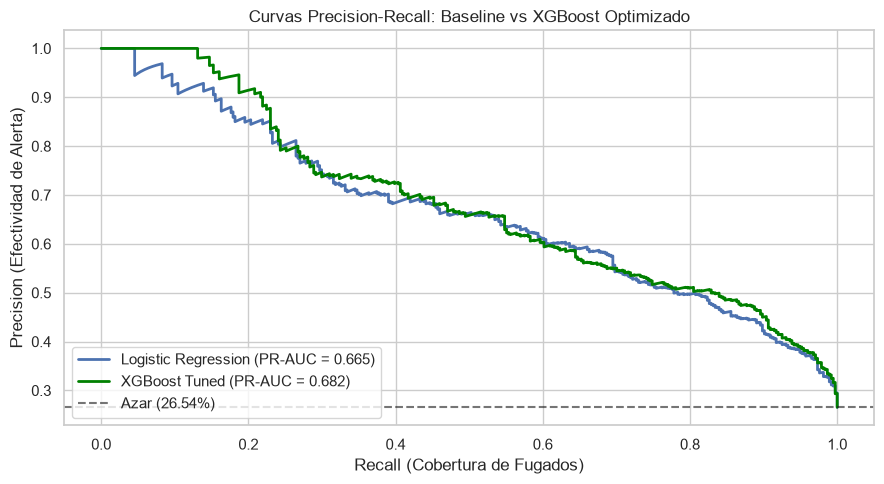

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))

# Curva LR
p_lr, r_lr, _ = precision_recall_curve(y_test, y_test_proba_lr)
ax.plot(r_lr, p_lr, label=f"Logistic Regression (PR-AUC = {average_precision_score(y_test, y_test_proba_lr):.3f})", lw=2)

# Curva XGBoost
p_xgb, r_xgb, _ = precision_recall_curve(y_test, y_test_proba_xgb)
ax.plot(r_xgb, p_xgb, label=f"XGBoost Tuned (PR-AUC = {average_precision_score(y_test, y_test_proba_xgb):.3f})", lw=2, color='green')

# Baseline aleatorio
ax.axhline(y=y_test.mean(), color='k', linestyle='--', alpha=0.6, label=f"Azar ({y_test.mean():.2%})")

ax.set_title("Curvas Precision-Recall: Baseline vs XGBoost Optimizado")
ax.set_xlabel("Recall (Cobertura de Fugados)")
ax.set_ylabel("Precision (Efectividad de Alerta)")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

### Impacto en el P&L y Estrategia Comercial

* **Precisión Perfecta en el Top de Riesgo:**
  * En la curva PR-AUC, `XGBoost Tuned` sostiene una **precisión del 100% hasta un Recall del ~14%**. Esto quiere decir que si se interviene al 14% de los clientes más propensos al abandono, **no habrá desperdicio en falsos positivos**. Cada contacto será un cliente que efectivamente estaba cancelando el servicio.
* **Ganador de Producción:**
  * Al superar el baseline de forma robusta y equilibrada, **`XGBoost_Tuned` es seleccionado y serializado** en `outputs/models/telecom_churn_pipeline.joblib` como el artefacto final para la API de inferencia.

### Empaquetar y Guardar el Pipeline Final para Producción

In [9]:
mejor_modelo_elegido = best_xgb if average_precision_score(y_test, y_test_proba_xgb) > average_precision_score(y_test, y_test_proba_lr) else lr

nombre_ganador = 'XGBoost_Tuned' if mejor_modelo_elegido == best_xgb else 'Logistic_Regression'

pipeline_final_produccion = Pipeline(
    steps=[('preprocessor', preprocesador),
           ('classifier', mejor_modelo_elegido)
           ]
)

pipeline_final_produccion.fit(X_train, y_train)

models_dir = Path('../outputs/models')
models_dir.mkdir(parents=True, exist_ok=True)
model_path = models_dir / 'telecom_churn_pipeline.joblib'

print(f'Modelo serializado: {nombre_ganador}')
joblib.dump(pipeline_final_produccion, model_path)
print(f'Pipeline de producción guardado con éxito en: {model_path}')

Modelo serializado: XGBoost_Tuned
Pipeline de producción guardado con éxito en: ..\outputs\models\telecom_churn_pipeline.joblib
